# Desafio Final — Análise Financeira ClearBank

**Disciplina:** Análise de Dados e Inteligência de Negócios com IA 

Este notebook lê e valida o arquivo `transacoes.csv` (exportado pela equipe de operações da ClearBank, cheio de problemas de qualidade), agrupa os dados limpos por mês, calcula métricas financeiras, sinaliza transações potencialmente suspeitas, exibe um relatório formatado no terminal e salva o resultado em `relatorio.json`.

**Fluxo do notebook:**
1. Preparação do arquivo de entrada (`transacoes.csv`)
2. Importação de módulos e constantes
3. Funções de leitura e validação
4. Funções de datas e métricas mensais
5. Funções de saída (JSON e relatório no terminal)
6. Célula de execução principal
7. Requisitos opcionais: pandas e matplotlib

## 1. Preparação do arquivo de entrada

O arquivo `transacoes.csv` deve conter **pelo menos 15 registros válidos** distribuídos em **3 ou mais meses**, **5 registros inválidos** (para testar a validação) e **pelo menos 2 transações acima de R$ 10.000,00**.

A célula abaixo cria o arquivo automaticamente caso ele ainda não exista, para o notebook funcionar tanto no Colab quanto localmente sem depender de upload manual:

In [1]:
# Conteúdo do arquivo de entrada com:
# - 12 registros válidos em 3 meses (2026-01, 2026-02, 2026-03)
# - 8 registros inválidos, um de cada tipo de erro coberto pela validação:
#   valor não numérico, cliente_id vazio, data mal formatada (2 casos),
#   valor negativo, valor zerado, id vazio e tipo inválido
# - 2 transações acima de R$ 10.000,00 (IDs 5 e 12)
DADOS_CSV = [
    "id,data,cliente_id,tipo,valor,descricao,categoria",
    "1,2026-01-05,CLI001,credito,3500.00,Salário janeiro,salario",
    "2,2026-01-12,CLI002,debito,180.50,Supermercado,compra",
    "3,2026-01-20,CLI001,debito,abc,Erro de sistema,compra",
    "4,2026-02-03,,debito,200.00,Sem cliente,transferencia",
    "5,2026-02-14,CLI003,credito,15000.00,Transferência suspeita,transferencia",
    "6,2026-02-18,CLI002,debito,320.00,Conta de luz,conta",
    "7,2026-03-01,CLI001,credito,3500.00,Salário março,salario",
    "8,2026-03-10,CLI003,debito,99.90,Streaming,assinatura",
    "9,2026-01-25,CLI002,credito,2200.00,Freelance janeiro,servico",
    "10,2026-02-27,CLI001,debito,850.00,Aluguel fevereiro,moradia",
    "11,31-01-2026,CLI003,debito,150.00,Data mal formatada,compra",
    "12,2026-02-09,CLI004,credito,12000.00,Pagamento contrato,transferencia",
    "13,2026-03-15,CLI002,credito,5100.75,Venda de equipamento,venda",
    "14,2026-03-22,CLI004,debito,-45.00,Valor negativo,compra",
    "15,2026-01-30,CLI003,credito,0.00,Valor zerado,servico",
    "16,,CLI001,debito,75.30,Sem id,transporte",
    "17,2026-02-21,CLI001,credito,2800.00,Reembolso despesas,reembolso",
    "18,2026-03-28,CLI003,debito,1250.40,Material escolar,educacao",
    "19,2026-15-40,CLI002,credito,900.00,Data impossivel,compra",
    "20,2026-03-31,CLI001,estorno,300.00,Tipo invalido,outros",
]

ARQ_CSV = "transacoes.csv"
ARQ_JSON = "relatorio.json"

import os

if not os.path.exists(ARQ_CSV):
    with open(ARQ_CSV, "w", encoding="utf-8", newline="") as f:
        f.write("\n".join(DADOS_CSV) + "\n")  # grava o conteúdo e cria o arquivo
    print(f"'{ARQ_CSV}' criado com {len(DADOS_CSV) - 1} registros de teste.")
else:
    print(f"'{ARQ_CSV}' já existe — usando o arquivo existente.")

'transacoes.csv' criado com 20 registros de teste.


## 2. Importação de módulos e constantes

Todos os módulos usados na solução principal são **nativos do Python** (`csv`, `json`, `datetime`) — nenhuma biblioteca externa é exigida. As bibliotecas externas (`pandas`, `matplotlib`) aparecem apenas nos requisitos opcionais, no final.

In [2]:
import csv
import json
from datetime import datetime

# Limite a partir do qual uma transação é marcada como suspeita
LIMITE_SUSPEITO = 10000.00

print("Módulos importados. LIMITE_SUSPEITO =", LIMITE_SUSPEITO)

Módulos importados. LIMITE_SUSPEITO = 10000.0


## 3. Leitura e validação dos dados

- `ler_transacoes()` usa o módulo nativo `csv` com `csv.DictReader` para acessar as colunas pelo nome, e trata o caso do arquivo inexistente.
- `validar_transacao()` valida uma única linha e devolve o registro limpo (ou `None`, se inválida), com try/except nas conversões de valor e data. Uma linha inválida é descartada silenciosamente, sem interromper o programa.

In [3]:
def ler_transacoes(caminho):
    """Lê o CSV com csv.DictReader e retorna a lista de transações brutas.

    Trata o caso do arquivo não existir (FileNotFoundError).
    """
    try:
        with open(caminho, newline="", encoding="utf-8") as f:
            leitor = csv.DictReader(f)
            return list(leitor)
    except FileNotFoundError:
        print(f"ERRO: arquivo '{caminho}' não encontrado.")
        raise

In [4]:
def validar_transacao(linha):
    """Valida uma única linha do CSV e retorna o registro limpo.

    Retorna None se a linha for inválida, sem interromper o programa.
    Regras: id numérico não vazio, cliente_id não vazio, data AAAA-MM-DD,
    tipo credito/debito e valor numérico maior que zero.
    """
    # id: vazio ou não numérico descarta a linha
    id_txt = (linha.get("id") or "").strip()
    if not id_txt or not id_txt.isdigit():
        return None
    # cliente_id: não pode ser vazio
    cliente = (linha.get("cliente_id") or "").strip()
    if not cliente:
        return None
    # data: precisa estar no formato AAAA-MM-DD (try/except 1)
    data_txt = (linha.get("data") or "").strip()
    try:
        data = datetime.strptime(data_txt, "%Y-%m-%d")
    except ValueError:
        return None
    # tipo: só credito ou debito
    tipo = (linha.get("tipo") or "").strip().lower()
    if tipo not in ("credito", "debito"):
        return None
    # valor: precisa ser numérico (try/except 2) e maior que zero
    try:
        valor = float((linha.get("valor") or "").strip())
    except ValueError:
        return None
    if valor <= 0:
        return None
    return {
        "id": int(id_txt),
        "data": data,
        "cliente_id": cliente,
        "tipo": tipo,
        "valor": valor,
        "descricao": (linha.get("descricao") or "").strip(),
        "categoria": (linha.get("categoria") or "").strip(),
    }

In [5]:
def validar_transacoes(transacoes):
    """Aplica validar_transacao() a todas as linhas.

    Retorna (lista de válidos, lista de inválidos, lista de suspeitas).
    """
    validos, invalidos, suspeitas = [], [], []
    for linha in transacoes:
        registro = validar_transacao(linha)
        if registro is None:
            invalidos.append(linha)
        else:
            validos.append(registro)
            if registro["valor"] > LIMITE_SUSPEITO:
                suspeitas.append(registro)
    return validos, invalidos, suspeitas

In [6]:
# --- Testes rápidos da validação ---
_teste_ok = {"id": "1", "data": "2026-01-05", "cliente_id": "CLI001",
             "tipo": "credito", "valor": "3500.00"}
_teste_valor_ruim = {"id": "3", "data": "2026-01-20", "cliente_id": "CLI001",
                     "tipo": "debito", "valor": "abc"}
_teste_data_ruim = {"id": "11", "data": "31-01-2026", "cliente_id": "CLI003",
                    "tipo": "debito", "valor": "150.00"}
print("Linha válida          ->", validar_transacao(_teste_ok))
print("Valor não numérico    ->", validar_transacao(_teste_valor_ruim))
print("Data mal formatada    ->", validar_transacao(_teste_data_ruim))

Linha válida          -> {'id': 1, 'data': datetime.datetime(2026, 1, 5, 0, 0), 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': 3500.0, 'descricao': '', 'categoria': ''}
Valor não numérico    -> None
Data mal formatada    -> None


## 4. Datas, agrupamento mensal e métricas

- `calcular_periodo()` devolve a data mais antiga, a mais recente e a quantidade de dias entre elas.
- `gerar_relatorio()` agrupa por mês (`AAAA-MM`, extraído com `strftime`) e calcula todas as métricas exigidas.

In [7]:
def calcular_periodo(transacoes):
    """Retorna (data mais antiga, data mais recente, dias entre elas)."""
    datas = [t["data"] for t in transacoes]
    mais_antiga = min(datas)
    mais_recente = max(datas)
    return mais_antiga, mais_recente, (mais_recente - mais_antiga).days

In [8]:
def gerar_relatorio(validos):
    """Agrupa as transações válidas por mês (AAAA-MM) e calcula:
    quantidade, total de crédito, total de débito, saldo, média,
    maior e menor valor."""
    resumo = {}
    for t in validos:
        mes = t["data"].strftime("%Y-%m")
        if mes not in resumo:
            resumo[mes] = {"quantidade": 0, "total_credito": 0.0,
                           "total_debito": 0.0, "valores": []}
        resumo[mes]["quantidade"] += 1
        resumo[mes][f"total_{t['tipo']}"] += t["valor"]
        resumo[mes]["valores"].append(t["valor"])

    for m in resumo.values():
        m["saldo"] = m["total_credito"] - m["total_debito"]
        m["media"] = sum(m["valores"]) / m["quantidade"]
        m["maior_valor"] = max(m["valores"])
        m["menor_valor"] = min(m["valores"])
        del m["valores"]  # lista auxiliar não vai para o resultado final
    return dict(sorted(resumo.items()))

In [9]:
# --- Teste rápido do agrupamento ---
_regs, _, _ = validar_transacoes(ler_transacoes(ARQ_CSV))
for _mes, _m in gerar_relatorio(_regs).items():
    print(_mes, "->", _m)

2026-01 -> {'quantidade': 3, 'total_credito': 5700.0, 'total_debito': 180.5, 'saldo': 5519.5, 'media': 1960.1666666666667, 'maior_valor': 3500.0, 'menor_valor': 180.5}
2026-02 -> {'quantidade': 5, 'total_credito': 29800.0, 'total_debito': 1170.0, 'saldo': 28630.0, 'media': 6194.0, 'maior_valor': 15000.0, 'menor_valor': 320.0}
2026-03 -> {'quantidade': 4, 'total_credito': 8600.75, 'total_debito': 1350.3000000000002, 'saldo': 7250.45, 'media': 2487.7625, 'maior_valor': 5100.75, 'menor_valor': 99.9}


## 5. Exportação em JSON e relatório no terminal

In [10]:
def salvar_json(dados, caminho):
    """Salva o relatório final em JSON com acentos corretos e indentação."""
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(dados, f, ensure_ascii=False, indent=2)
    print(f"Relatório salvo em '{caminho}'.")

In [11]:
def formatar_moeda(valor):
    """Formata um número no padrão monetário brasileiro: R$ 1.234,56."""
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [12]:
def exibir_relatorio(dados, validos, suspeitas):
    """Imprime o relatório formatado no terminal."""
    antiga, recente, dias = calcular_periodo(validos)

    print("=" * 40)
    print("==== RELATÓRIO MENSAL ====".center(40))
    print("=" * 40)
    print(f"Período analisado: {antiga.strftime('%d/%m/%Y')} → "
          f"{recente.strftime('%d/%m/%Y')} ({dias} dias)")
    print(f"Transações válidas:   {dados['total_transacoes_validas']}")
    print(f"Transações inválidas: {dados['total_transacoes_invalidas']}")

    for mes, m in dados["resumo_mensal"].items():
        print("\n" + "-" * 40)
        print(f"Mês: {mes}")
        print("-" * 40)
        print(f"  Transações: {m['quantidade']}")
        print(f"  Total crédito: {formatar_moeda(m['total_credito'])}")
        print(f"  Total débito:  {formatar_moeda(m['total_debito'])}")
        print(f"  Saldo:         {formatar_moeda(m['saldo'])}")
        print(f"  Média:         {formatar_moeda(m['media'])}")
        print(f"  Maior valor:   {formatar_moeda(m['maior_valor'])}")
        print(f"  Menor valor:   {formatar_moeda(m['menor_valor'])}")

    print("\n" + "=" * 40)
    print("==== TRANSAÇÕES SUSPEITAS ====".center(40))
    print("=" * 40)
    if suspeitas:
        for t in suspeitas:
            print(f"ID: {t['id']} | Cliente: {t['cliente_id']} | "
                  f"Data: {t['data'].strftime('%Y-%m-%d')} | "
                  f"Valor: {formatar_moeda(t['valor'])}")
    else:
        print("Nenhuma transação suspeita encontrada.")

## 6. Célula de Execução Principal

Chama todas as funções em sequência: leitura → validação → métricas → JSON → relatório.

In [13]:
# ===== CÉLULA DE EXECUÇÃO PRINCIPAL =====
print("Iniciando análise financeira ClearBank...\n")

# 1. Leitura
transacoes_brutas = ler_transacoes(ARQ_CSV)
print(f"Total de linhas lidas: {len(transacoes_brutas)}")

# 2. Validação e limpeza
validas, invalidas, suspeitas = validar_transacoes(transacoes_brutas)
print(f"Linhas válidas:   {len(validas)}")
print(f"Linhas inválidas: {len(invalidas)}\n")

# 3. Métricas mensais
resumo_mensal = gerar_relatorio(validas)

# 4. Montagem do dicionário final
relatorio = {
    "gerado_em": datetime.now().strftime("%Y-%m-%d"),
    "total_transacoes_validas": len(validas),
    "total_transacoes_invalidas": len(invalidas),
    "resumo_mensal": resumo_mensal,
    "transacoes_suspeitas": [
        {"id": t["id"], "cliente_id": t["cliente_id"],
         "data": t["data"].strftime("%Y-%m-%d"), "valor": round(t["valor"], 2)}
        for t in suspeitas
    ],
}

# 5. Exportação e exibição
salvar_json(relatorio, ARQ_JSON)
exibir_relatorio(relatorio, validas, suspeitas)

Iniciando análise financeira ClearBank...

Total de linhas lidas: 20
Linhas válidas:   12
Linhas inválidas: 8

Relatório salvo em 'relatorio.json'.
       ==== RELATÓRIO MENSAL ====       
Período analisado: 05/01/2026 → 28/03/2026 (82 dias)
Transações válidas:   12
Transações inválidas: 8

----------------------------------------
Mês: 2026-01
----------------------------------------
  Transações: 3
  Total crédito: R$ 5.700,00
  Total débito:  R$ 180,50
  Saldo:         R$ 5.519,50
  Média:         R$ 1.960,17
  Maior valor:   R$ 3.500,00
  Menor valor:   R$ 180,50

----------------------------------------
Mês: 2026-02
----------------------------------------
  Transações: 5
  Total crédito: R$ 29.800,00
  Total débito:  R$ 1.170,00
  Saldo:         R$ 28.630,00
  Média:         R$ 6.194,00
  Maior valor:   R$ 15.000,00
  Menor valor:   R$ 320,00

----------------------------------------
Mês: 2026-03
----------------------------------------
  Transações: 4
  Total crédito: R$ 8.600,75

## 7. Requisitos Opcionais

### RO1 — Análise com pandas

A versão completa está no arquivo separado `analise_pandas.py`, como pede o enunciado. A célula abaixo executa esse script e exibe o resultado da comparação com a solução nativa:

In [14]:
# ===== REQUISITO OPCIONAL 1: pandas =====
# Requer: pip install pandas (o Colab já possui)
!python analise_pandas.py

pandas -> linhas lidas: 20 | válidas: 12 | inválidas: 8
  2026-01: {'quantidade': 3, 'total_credito': 5700.0, 'total_debito': 180.5, 'saldo': 5519.5, 'media': 1960.17, 'maior_valor': 3500.0, 'menor_valor': 180.5}
  2026-02: {'quantidade': 5, 'total_credito': 29800.0, 'total_debito': 1170.0, 'saldo': 28630.0, 'media': 6194.0, 'maior_valor': 15000.0, 'menor_valor': 320.0}
  2026-03: {'quantidade': 4, 'total_credito': 8600.75, 'total_debito': 1350.3, 'saldo': 7250.45, 'media': 2487.76, 'maior_valor': 5100.75, 'menor_valor': 99.9}

Comparação com a solução nativa:
  Totais de transações iguais: True
  Resumo mensal idêntico:      True

Suspeitas (> R$ 10.000,00):
  ID 5 | CLI003 | 2026-02-14 | R$ 15.000,00
  ID 12 | CLI004 | 2026-02-09 | R$ 12.000,00


### RO2 — Visualização com matplotlib

Gráfico de barras empilhadas com crédito e débito por mês (Opção C do enunciado), salvo como `grafico.png`:

Gráfico salvo em 'grafico.png'.


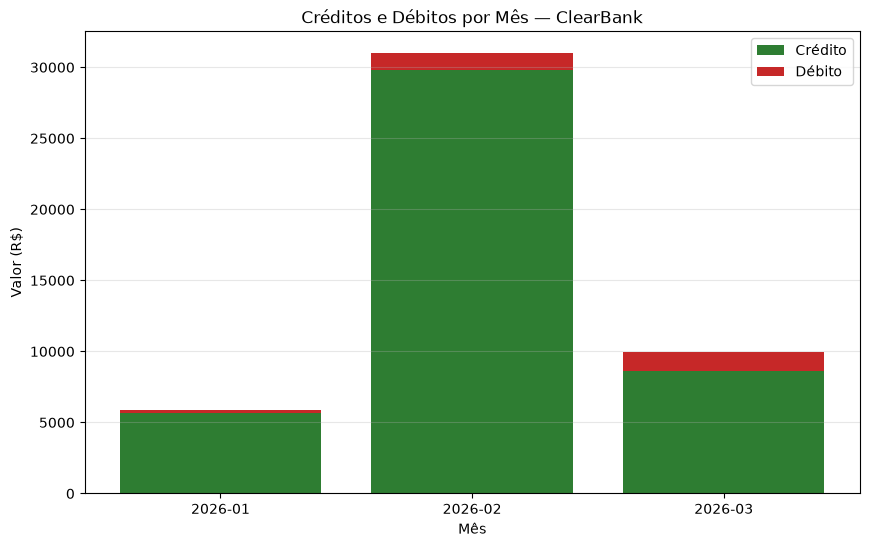

In [15]:
# ===== REQUISITO OPCIONAL 2: matplotlib =====
# Requer: pip install matplotlib (o Colab já possui)
import matplotlib.pyplot as plt

meses = list(resumo_mensal.keys())
creditos = [m["total_credito"] for m in resumo_mensal.values()]
debitos = [m["total_debito"] for m in resumo_mensal.values()]

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(meses, creditos, label="Crédito", color="#2e7d32")
ax.bar(meses, debitos, bottom=creditos, label="Débito", color="#c62828")
ax.set_title("Créditos e Débitos por Mês — ClearBank")
ax.set_xlabel("Mês")
ax.set_ylabel("Valor (R$)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.savefig("grafico.png", dpi=150, bbox_inches="tight")
print("Gráfico salvo em 'grafico.png'.")
plt.show()